# 01 - Exploratory Data Analysis

Goal: understand the network KPI data before building a model. We look for daily patterns, relationships between KPIs, and how anomalies differ from normal readings.

Run the cells top to bottom with **Shift + Enter**.

In [10]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True

# The notebook runs from the notebooks/ folder, so the database is one level up.
DB_PATH = Path("../data/teleq.db")

with sqlite3.connect(DB_PATH) as conn:
    df = pd.read_sql_query(
        "SELECT k.*, c.region, c.tower_type FROM kpis k JOIN cells c ON c.cell_id = k.cell_id",
        conn,
        parse_dates=["timestamp"],
    )

df["hour"] = df["timestamp"].dt.hour
df.head()

,id,timestamp,cell_id,latency_ms,throughput_mbps,signal_dbm,packet_loss_pct,active_users,is_anomaly,region,tower_type,hour
0,1,2026-09-01 00:00:00,CELL_001,34.28,92.38,-77.10,0.40,57,0,North,Macro,0
1,2,2026-09-01 01:00:00,CELL_001,28.35,110.50,-83.72,0.88,37,0,North,Macro,1
2,3,2026-09-01 02:00:00,CELL_001,25.95,101.89,-84.00,0.50,36,0,North,Macro,2
3,4,2026-09-01 03:00:00,CELL_001,34.40,85.42,-79.85,0.05,33,0,North,Macro,3
4,5,2026-09-01 04:00:00,CELL_001,36.61,95.97,-79.31,0.57,45,0,North,Macro,4


## 1. Basic shape and summary statistics

In [11]:
print(df.shape)
df.info()

(14400, 12)
<class 'pandas.DataFrame'>
RangeIndex: 14400 entries, 0 to 14399
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id               14400 non-null  int64         
 1   timestamp        14400 non-null  datetime64[us]
 2   cell_id          14400 non-null  str           
 3   latency_ms       14400 non-null  float64       
 4   throughput_mbps  14400 non-null  float64       
 5   signal_dbm       14400 non-null  float64       
 6   packet_loss_pct  14400 non-null  float64       
 7   active_users     14400 non-null  int64         
 8   is_anomaly       14400 non-null  int64         
 9   region           14400 non-null  str           
 10  tower_type       14400 non-null  str           
 11  hour             14400 non-null  int32         
dtypes: datetime64[us](1), float64(4), int32(1), int64(3), str(3)
memory usage: 1.3 MB


In [12]:
df[["latency_ms", "throughput_mbps", "signal_dbm", "packet_loss_pct", "active_users"]].describe().round(2)

,latency_ms,throughput_mbps,signal_dbm,packet_loss_pct,active_users
count,14400.00,14400.00,14400.00,14400.00,14400.00
mean,34.79,91.60,-80.15,0.55,56.47
std,11.69,15.17,4.43,0.77,23.54
min,14.78,3.41,-114.39,0.00,12.00
25%,29.12,82.00,-82.77,0.37,39.00
50%,32.78,93.93,-80.08,0.50,47.50
75%,38.95,102.39,-77.38,0.64,76.00
max,250.81,132.21,-62.69,14.89,123.00


## 2. Daily pattern: users and latency by hour
Question: does network load follow a daily cycle, and does latency follow it?

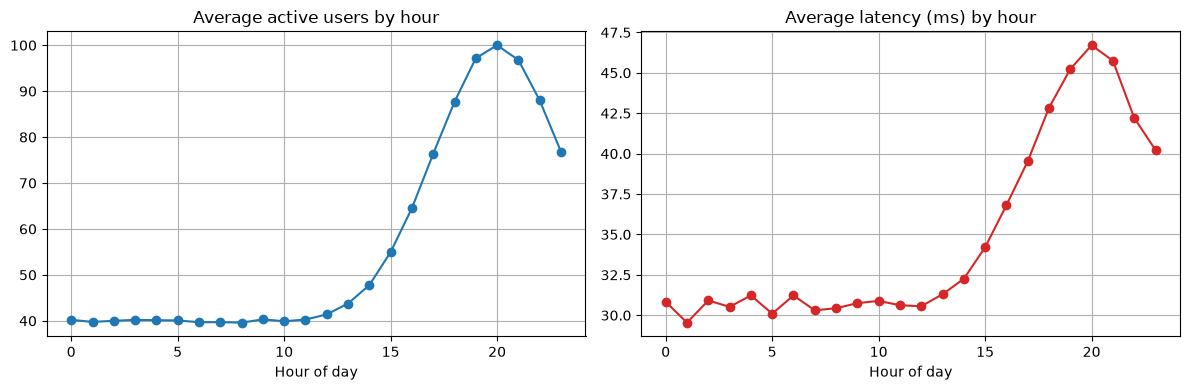

In [13]:
hourly = df.groupby("hour")[["active_users", "latency_ms", "throughput_mbps"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hourly["active_users"].plot(ax=axes[0], marker="o", title="Average active users by hour")
hourly["latency_ms"].plot(ax=axes[1], marker="o", color="tab:red", title="Average latency (ms) by hour")
for ax in axes:
    ax.set_xlabel("Hour of day")
plt.tight_layout()
plt.show()

## 3. Load vs latency
More users should mean higher latency. Anomalies (red) should sit away from the main cloud.

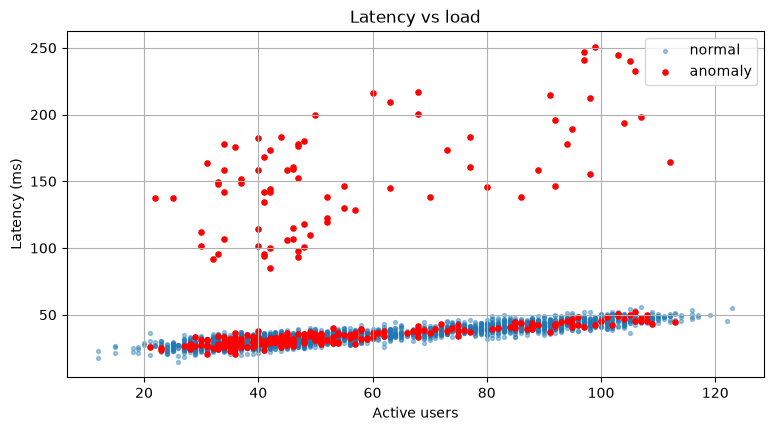

In [14]:
normal = df[df["is_anomaly"] == 0].sample(3000, random_state=1)
anom = df[df["is_anomaly"] == 1]

plt.scatter(normal["active_users"], normal["latency_ms"], s=8, alpha=0.4, label="normal")
plt.scatter(anom["active_users"], anom["latency_ms"], s=14, color="red", label="anomaly")
plt.xlabel("Active users")
plt.ylabel("Latency (ms)")
plt.title("Latency vs load")
plt.legend()
plt.show()

## 4. Distributions: normal vs anomalous

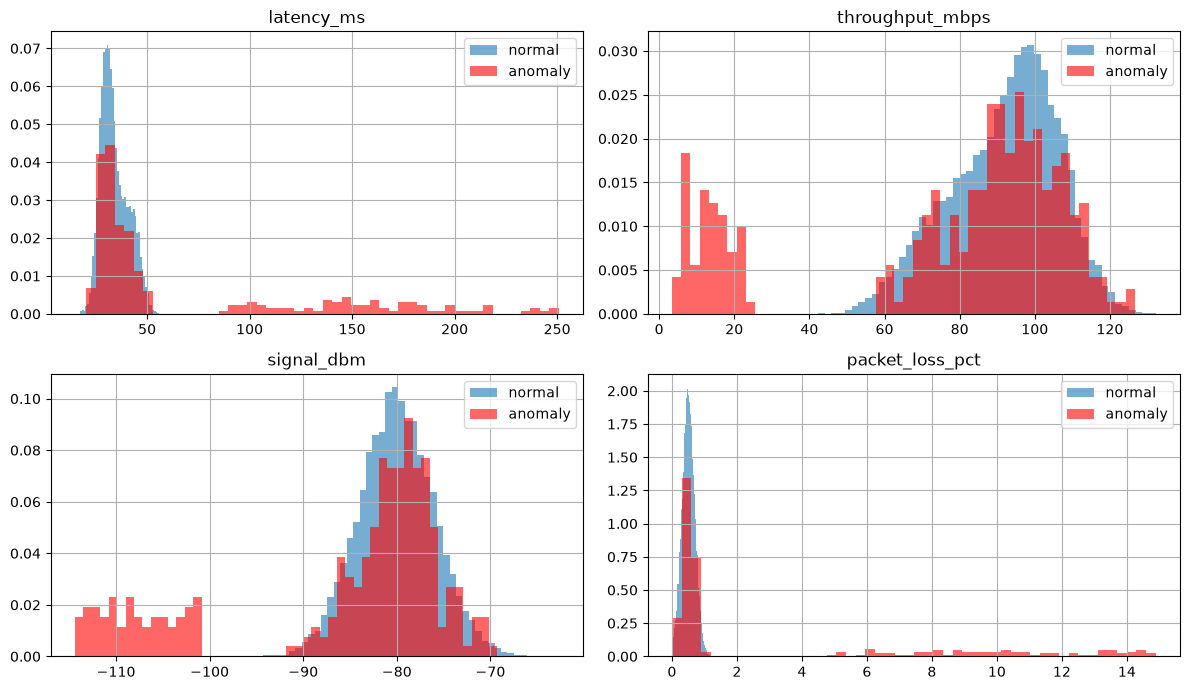

In [15]:
cols = ["latency_ms", "throughput_mbps", "signal_dbm", "packet_loss_pct"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, col in zip(axes.ravel(), cols):
    ax.hist(df.loc[df["is_anomaly"] == 0, col], bins=50, alpha=0.6, density=True, label="normal")
    ax.hist(df.loc[df["is_anomaly"] == 1, col], bins=50, alpha=0.6, density=True, color="red", label="anomaly")
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.show()

## 5. Correlations between KPIs

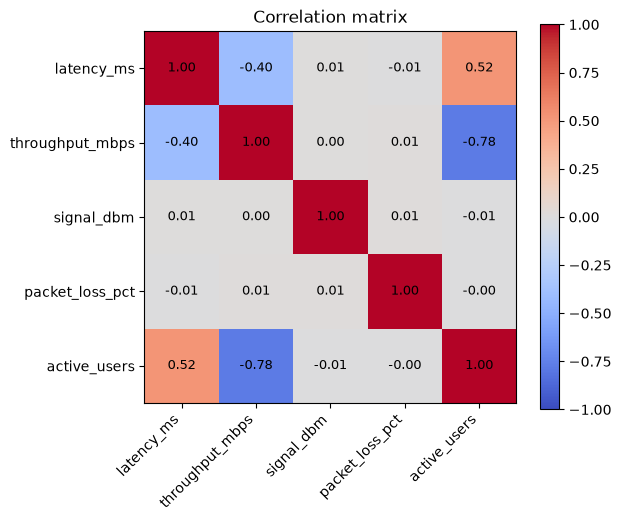

In [16]:
num_cols = ["latency_ms", "throughput_mbps", "signal_dbm", "packet_loss_pct", "active_users"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im)
ax.set_title("Correlation matrix")
ax.grid(False)
plt.show()

## 6. Anomalies by cell and by region

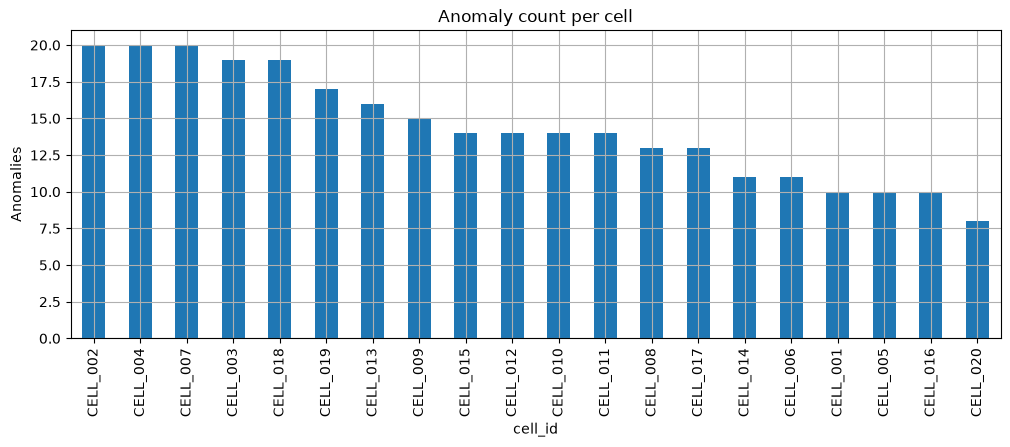

region
Central    1.94
East       1.81
North      2.19
South      2.08
West       2.04
Name: is_anomaly, dtype: float64

In [17]:
by_cell = df.groupby("cell_id")["is_anomaly"].sum().sort_values(ascending=False)
by_cell.plot(kind="bar", figsize=(12, 4), title="Anomaly count per cell")
plt.ylabel("Anomalies")
plt.show()

df.groupby("region")["is_anomaly"].mean().mul(100).round(2)

## 7. Why raw values are not enough (key insight for the model)
Use the cell below to compare latency at the quietest hour with latency at the busiest hour.

In [18]:
quiet = df[df["hour"] == 4]["latency_ms"]
busy = df[df["hour"] == 20]["latency_ms"]
print(f"Latency at 4 AM:  mean {quiet.mean():.1f} ms, 95th percentile {quiet.quantile(.95):.1f} ms")
print(f"Latency at 8 PM:  mean {busy.mean():.1f} ms, 95th percentile {busy.quantile(.95):.1f} ms")

Latency at 4 AM:  mean 31.2 ms, 95th percentile 36.2 ms
Latency at 8 PM:  mean 46.7 ms, 95th percentile 51.0 ms


## My observations
*Write 4-5 bullet points here in your own words (daily pattern, correlations, how anomalies look different, what surprised you).*
-the hour when users peak is 20(8 pm),and the latency follows quite closely during the eveing
-latency, packet loss, and signal strength, because their anomaly distributions show clear separation from normal behavior. Throughput also shows a noticeable difference.
-CELL_002, CELL_004, and CELL_007 are the cells to investigate first because they have the highest anomaly counts.

